# 1. Setup and ingestion

In [3]:
import os
import numpy as np
import pandas as pd
import scipy.optimize as sco
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import warnings

# Configure warnings and plot aesthetics
warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", palette="tab10")
plt.rcParams['figure.figsize'] = (16, 8)

# Define Directory Paths (Relative to this notebook)
BASE_DIR = r"C:\Users\sudha\Downloads\US_Custom_Indices_Project"
DATA_DIR = os.path.join(BASE_DIR, "data", "processed")
OUT_DIR_DATA = os.path.join(BASE_DIR, "outputs", "indices_data")
OUT_DIR_VIZ = os.path.join(BASE_DIR, "outputs", "visuals")

# Ensure output directories exist
os.makedirs(OUT_DIR_DATA, exist_ok=True)
os.makedirs(OUT_DIR_VIZ, exist_ok=True)

# Define file paths
PRICES_FILE = os.path.join(DATA_DIR, "historical_prices_2015_2026.parquet")
MCAP_FILE = os.path.join(DATA_DIR, "market_cap_classifications.parquet")
SECTORS_FILE = os.path.join(DATA_DIR, "ticker_sectors.csv")

print("✅ Environment successfully initialized. Output directories verified.")

✅ Environment successfully initialized. Output directories verified.


# 2. DATA INGESTION, OUTLIER SANITIZATION and Index Construction Engine 

In [4]:
print("Loading master data files...")

# 1. Load Parquet datasets using pd.read_parquet
df_prices = pd.read_parquet(PRICES_FILE)
df_mcap = pd.read_parquet(MCAP_FILE)

# 2. Safe loading of Sector Data (handling CSV encoding & fallback)
if os.path.exists(SECTORS_FILE):
    try:
        df_sectors = pd.read_csv(SECTORS_FILE, encoding='utf-8')
    except UnicodeDecodeError:
        # Fallback if saved with Windows ANSI/CP1252 encoding
        df_sectors = pd.read_csv(SECTORS_FILE, encoding='latin1')
    sector_map = df_sectors.set_index('Ticker')['Sector'].to_dict()
    print("✅ Sector classifications successfully loaded.")
else:
    print("⚠️ ticker_sectors.csv not found in processed folder. Using 'General' as fallback.")
    sector_map = {t: 'General' for t in df_mcap['Ticker']}

# 3. Pivot Prices & Calculate Daily Returns
print("Pivoting prices and calculating returns...")
price_matrix = df_prices.pivot(index='Date', columns='Ticker', values='Adj Close').ffill()
stock_returns = price_matrix.pct_change()

# 4. Construct Market Cap & Float Weighting Matrices
shifted_prices = price_matrix.shift(1)

shares_out = df_mcap.set_index('Ticker')['Shares Outstanding'].to_dict()
float_out = df_mcap.set_index('Ticker')['Float Shares'].to_dict()
size_map = df_mcap.set_index('Ticker')['Market Cap Category'].to_dict()

shares_matrix = pd.DataFrame({col: shares_out.get(col, np.nan) for col in price_matrix.columns}, index=price_matrix.index)
float_matrix = pd.DataFrame({col: float_out.get(col, np.nan) for col in price_matrix.columns}, index=price_matrix.index)

historical_mcap = shifted_prices * shares_matrix
historical_float_mcap = shifted_prices * float_matrix

# 5. Outlier Detection Filter (Stripping the >$10T API data glitches)
GLITCH_THRESHOLD = 10_000_000_000_000 
max_mcaps = historical_mcap.max()
glitch_tickers = max_mcaps[max_mcaps > GLITCH_THRESHOLD].index.tolist()

if glitch_tickers:
    print(f"🧹 Removing {len(glitch_tickers)} data anomalies (> $10T): {glitch_tickers}")
    historical_mcap = historical_mcap.drop(columns=glitch_tickers, errors='ignore')
    historical_float_mcap = historical_float_mcap.drop(columns=glitch_tickers, errors='ignore')
    stock_returns = stock_returns.drop(columns=glitch_tickers, errors='ignore')
    price_matrix = price_matrix.drop(columns=glitch_tickers, errors='ignore')
    shifted_prices = shifted_prices.drop(columns=glitch_tickers, errors='ignore')

print(f"✅ Data clean & ready. Operating on {len(stock_returns.columns)} assets across {len(stock_returns)} dates.")

Loading master data files...
✅ Sector classifications successfully loaded.
Pivoting prices and calculating returns...
🧹 Removing 2 data anomalies (> $10T): ['TNXP', 'USB.BA']
✅ Data clean & ready. Operating on 1505 assets across 3035 dates.


# 3. Portfolio Generation
Using the Index Factory, we generate a suite of core benchmarks, thematic plays, and Smart Beta portfolios.

In [5]:
def build_index(name, weighting='MCW', target_sizes=None, target_sectors=None, exclude_sectors=None, top_n=None):
    """
    Constructs a daily return series for a custom index based on specific parameters.
    
    Parameters:
    - name (str): The name of your custom index.
    - weighting (str): 'MCW', 'Float-MCW', 'EW', 'PW', or 'InvVol'.
    - target_sizes (list): e.g., ['Mega-Cap', 'Large-Cap']. None means all sizes.
    - target_sectors (list): e.g., ['Technology']. None means all sectors.
    - exclude_sectors (list): e.g., ['Technology']. Excludes these sectors.
    - top_n (int): Dynamically pick the top N largest stocks every day.
    
    Returns:
    - pd.Series: Daily index returns.
    """
    # 1. Filter the Universe (Columns)
    valid_cols = stock_returns.columns.tolist()
    
    if target_sizes:
        valid_cols = [t for t in valid_cols if size_map.get(t) in target_sizes]
    if target_sectors:
        valid_cols = [t for t in valid_cols if sector_map.get(t) in target_sectors]
    if exclude_sectors:
        valid_cols = [t for t in valid_cols if sector_map.get(t) not in exclude_sectors]
        
    if not valid_cols:
        raise ValueError(f"No stocks found for {name} with given filters!")
        
    # Isolate data for just these stocks
    sub_returns = stock_returns[valid_cols]
    sub_mcap = historical_mcap[valid_cols]
    
    # 2. Dynamic Top N Filtering (if requested)
    if top_n:
        daily_ranks = sub_mcap.rank(axis=1, ascending=False)
        mask = daily_ranks <= top_n
        sub_returns = sub_returns.where(mask, 0)
        sub_mcap = sub_mcap.where(mask, 0)
        
    # 3. Apply Weighting Schemes
    if weighting == 'MCW':
        weights = sub_mcap.div(sub_mcap.sum(axis=1), axis=0)
        
    elif weighting == 'Float-MCW':
        sub_float = historical_float_mcap[valid_cols]
        if top_n:
            sub_float = sub_float.where(mask, 0)
        weights = sub_float.div(sub_float.sum(axis=1), axis=0)
        
    elif weighting == 'EW': # Equal Weight
        # Identify which stocks are "alive" and actively trading on a given day
        is_active = sub_returns.notna() & (sub_mcap > 0)
        active_count = is_active.sum(axis=1)
        weights = is_active.div(active_count, axis=0)
        
    elif weighting == 'PW': # Price Weight (Dow Jones Style)
        sub_prices = shifted_prices[valid_cols]
        if top_n:
            sub_prices = sub_prices.where(mask, 0)
        weights = sub_prices.div(sub_prices.sum(axis=1), axis=0)
        
    elif weighting == 'InvVol': # Inverse Volatility (Smart Beta)
        rolling_vol = sub_returns.rolling(window=252).std()
        inv_vol = 1.0 / rolling_vol
        if top_n:
            inv_vol = inv_vol.where(mask, 0)
        weights = inv_vol.div(inv_vol.sum(axis=1), axis=0)
        
    else:
        raise ValueError("Invalid weighting scheme!")

    # 4. Calculate Final Daily Returns
    daily_idx_ret = (weights * sub_returns).sum(axis=1).fillna(0)
    daily_idx_ret.name = name
    return daily_idx_ret

print("✅ Index Factory function initialized and ready.")

✅ Index Factory function initialized and ready.


# 4. Aggregation & Metrics
## 4.1 Normalization & Dashboard
Rebasing all indices to 100 on the start date and calculating quantitative risk/return metrics (CAGR, Volatility, Sharpe, Drawdown).

In [6]:
print("Generating Custom Portfolios...")
portfolio_returns = {}

# --- CATEGORY 1: CORE BENCHMARKS ---
portfolio_returns['1. Total Market (MCW)'] = build_index('Total Market (MCW)', weighting='MCW')
portfolio_returns['2. Total Market (Float-MCW)'] = build_index('Total Market (Float-MCW)', weighting='Float-MCW')
portfolio_returns['3. Total Market (EW)'] = build_index('Total Market (EW)', weighting='EW')

# --- CATEGORY 2: SIZE & CONCENTRATION ---
portfolio_returns['4. S&P 500 Proxy (Top 500 MCW)'] = build_index('Top 500 Proxy', weighting='MCW', top_n=500)
portfolio_returns['5. The Goliath Index (Top 50 EW)'] = build_index('Goliath (Top 50 EW)', weighting='EW', top_n=50)
portfolio_returns['6. Mid-Cap Engine (MCW)'] = build_index('Mid-Cap Engine', weighting='MCW', target_sizes=['Mid-Cap'])
portfolio_returns['7. Micro-Cap Moonshots (MCW)'] = build_index('Micro-Cap Moonshots', weighting='MCW', target_sizes=['Micro-Cap', 'Nano-Cap'])

# --- CATEGORY 3: SECTOR & THEMATIC PLAYS ---
portfolio_returns['8. Ex-Tech Economy (MCW)'] = build_index(
    'Ex-Tech Economy', weighting='MCW', exclude_sectors=['Technology', 'Communication Services'])

portfolio_returns['9. SWAN Defensive (InvVol)'] = build_index(
    'SWAN Defensive', weighting='InvVol', target_sectors=['Healthcare', 'Utilities', 'Consumer Defensive'])

portfolio_returns['10. Pure Tech (EW)'] = build_index(
    'Pure Tech (EW)', weighting='EW', target_sectors=['Technology'])

portfolio_returns['11. Small-Cap Innovators (Float-MCW)'] = build_index(
    'Small-Cap Innovators', weighting='Float-MCW', target_sectors=['Technology', 'Healthcare'], target_sizes=['Small-Cap'])

# --- CATEGORY 4: SMART BETA & RISK PLAYS ---
portfolio_returns['12. Smart Beta (Inverse Volatility)'] = build_index('Smart Beta (Inv Vol)', weighting='InvVol')
portfolio_returns['13. The High-Beta Rollercoaster (PW)'] = build_index('High-Beta Speculative', weighting='PW', target_sizes=['Small-Cap', 'Micro-Cap'])

# --- CATEGORY 5: MATHEMATICAL OPTIMIZATION (GMV) ---
def build_gmv_index(top_n=100):
    """Calculates the Global Minimum Variance portfolio for the top N stocks."""
    top_tickers = historical_mcap.sum().nlargest(top_n).index.tolist()
    
    # Require 95% data completeness for covariance stability, fill remaining with 0
    min_days = int(len(stock_returns) * 0.95)
    clean_returns = stock_returns[top_tickers].dropna(axis=1, thresh=min_days).fillna(0)
    
    cov_matrix = clean_returns.cov() * 252
    num_assets = len(clean_returns.columns)
    
    def variance(weights): return weights.T @ cov_matrix @ weights
    bounds = tuple((0, 1) for _ in range(num_assets))
    constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
    
    opt_res = sco.minimize(variance, num_assets*[1./num_assets], method='SLSQP', bounds=bounds, constraints=constraints)
    
    # Calculate daily returns using the static optimal weights
    return (clean_returns * opt_res.x).sum(axis=1).fillna(0)

portfolio_returns['14. Global Minimum Variance (Top 100)'] = build_gmv_index(top_n=100)

# Combine all into one Master DataFrame
master_returns_df = pd.DataFrame(portfolio_returns)
print(f"✅ Successfully generated {len(master_returns_df.columns)} custom indices!")

Generating Custom Portfolios...
✅ Successfully generated 14 custom indices!


# 5. Visualization & Export

In [7]:
BASE_VALUE = 100
TRADING_DAYS = 252
RISK_FREE_RATE = 0.02

# 1. Base-100 Normalization
master_index_values = BASE_VALUE * (1 + master_returns_df).cumprod()

# 2. Calculate Dashboard Metrics
metrics = []
for col in master_returns_df.columns:
    ret = master_returns_df[col].dropna()
    val = master_index_values[col].dropna()
    
    # CAGR
    years = len(ret) / TRADING_DAYS
    cagr = ((val.iloc[-1] / BASE_VALUE) ** (1 / years)) - 1
    
    # Volatility & Sharpe
    vol = ret.std() * np.sqrt(TRADING_DAYS)
    sharpe = (cagr - RISK_FREE_RATE) / vol if vol > 0 else 0
    
    # Max Drawdown
    rolling_max = val.cummax()
    drawdown = (val / rolling_max) - 1
    max_dd = drawdown.min()
    
    metrics.append({
        'Index Name': col,
        'CAGR': cagr,
        'Volatility': vol,
        'Sharpe Ratio': sharpe,
        'Max Drawdown': max_dd
    })

# Format the Dashboard beautifully
dashboard_df = pd.DataFrame(metrics).set_index('Index Name')
styled_dashboard = dashboard_df.style.format({
    'CAGR': '{:.2%}',
    'Volatility': '{:.2%}',
    'Sharpe Ratio': '{:.2f}',
    'Max Drawdown': '{:.2%}'
}).background_gradient(subset=['CAGR', 'Sharpe Ratio'], cmap='Greens') \
  .background_gradient(subset=['Volatility', 'Max Drawdown'], cmap='Reds_r')

print("\n=== PROFESSIONAL INDEX PERFORMANCE DASHBOARD ===")
display(styled_dashboard)


=== PROFESSIONAL INDEX PERFORMANCE DASHBOARD ===


,CAGR,Volatility,Sharpe Ratio,Max Drawdown
Index Name,,,,
1. Total Market (MCW),13.36%,17.91%,0.63,-33.56%
2. Total Market (Float-MCW),12.38%,18.92%,0.55,-33.84%
3. Total Market (EW),19.65%,21.59%,0.82,-40.76%
4. S&P 500 Proxy (Top 500 MCW),13.23%,17.79%,0.63,-32.82%
5. The Goliath Index (Top 50 EW),13.70%,17.46%,0.67,-31.30%
6. Mid-Cap Engine (MCW),2.73%,21.95%,0.03,-47.88%
7. Micro-Cap Moonshots (MCW),-34.22%,162.14%,-0.22,-99.78%
8. Ex-Tech Economy (MCW),10.04%,16.48%,0.49,-34.89%
9. SWAN Defensive (InvVol),13.00%,15.27%,0.72,-29.72%


Generating Professional Visualization Suite...


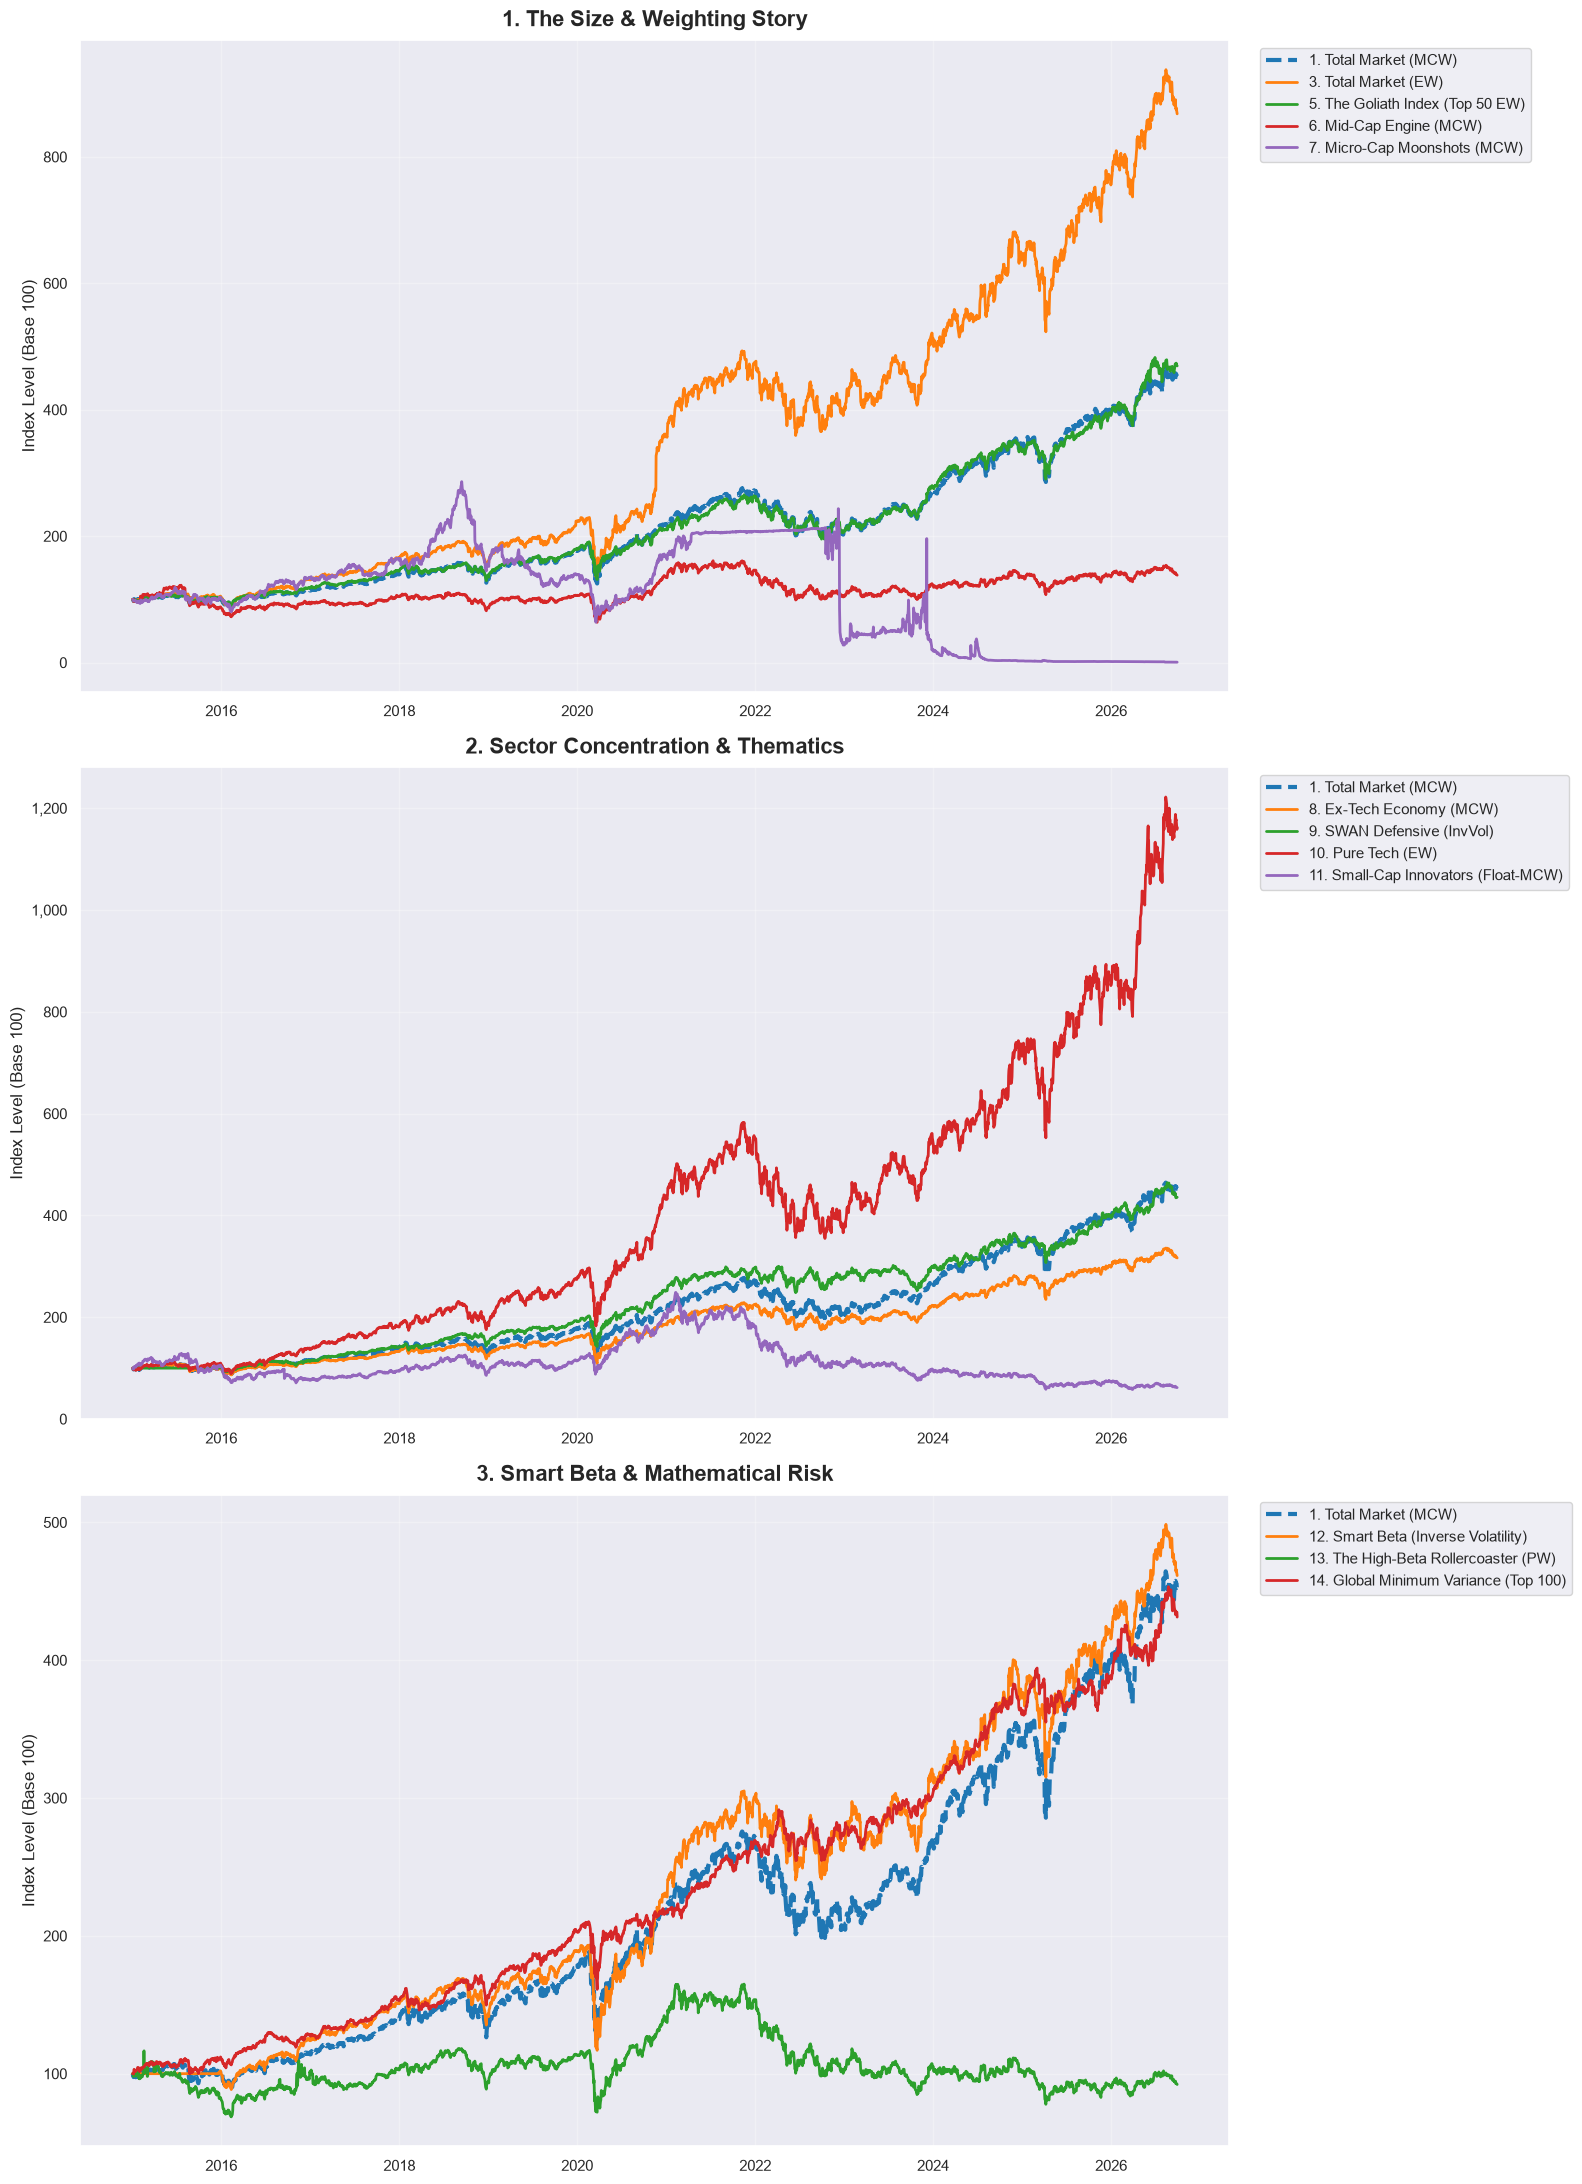


Exporting Master Indices for Dash Application...
✅ Success! Master files saved to:
 - C:\Users\sudha\Downloads\US_Custom_Indices_Project\outputs\indices_data\Master_Custom_Indices.parquet
 - C:\Users\sudha\Downloads\US_Custom_Indices_Project\outputs\indices_data\Master_Custom_Indices.csv


In [8]:
print("Generating Professional Visualization Suite...")

# Define the logical groupings for our charts
plot_groups = {
    "1. The Size & Weighting Story": [
        '1. Total Market (MCW)', 
        '3. Total Market (EW)', 
        '5. The Goliath Index (Top 50 EW)', 
        '6. Mid-Cap Engine (MCW)', 
        '7. Micro-Cap Moonshots (MCW)'
    ],
    "2. Sector Concentration & Thematics": [
        '1. Total Market (MCW)', 
        '8. Ex-Tech Economy (MCW)', 
        '9. SWAN Defensive (InvVol)', 
        '10. Pure Tech (EW)', 
        '11. Small-Cap Innovators (Float-MCW)'
    ],
    "3. Smart Beta & Mathematical Risk": [
        '1. Total Market (MCW)', 
        '12. Smart Beta (Inverse Volatility)', 
        '13. The High-Beta Rollercoaster (PW)', 
        '14. Global Minimum Variance (Top 100)'
    ]
}

# Create a 3-row, 1-column figure
fig, axes = plt.subplots(3, 1, figsize=(16, 22))

for ax, (title, indices) in zip(axes, plot_groups.items()):
    for col in indices:
        # Check if the column exists to prevent typos from crashing the plot
        if col in master_index_values.columns:
            # Make the Total Market baseline thicker and dashed so it stands out
            lw = 3 if 'Total Market (MCW)' in col else 2
            ls = '--' if 'Total Market (MCW)' in col else '-'
            ax.plot(master_index_values.index, master_index_values[col], label=col, linewidth=lw, linestyle=ls)
    
    ax.set_title(title, fontsize=16, fontweight='bold', pad=10)
    ax.set_ylabel("Index Level (Base 100)", fontsize=12)
    ax.legend(fontsize=11, loc='upper left', bbox_to_anchor=(1.02, 1)) # Puts legend cleanly outside the chart
    ax.grid(True, alpha=0.3)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

# --- FINAL DATA EXPORT ---
print("\nExporting Master Indices for Dash Application...")

# Move dates from index to a column for database friendliness
final_export_df = master_index_values.reset_index()

export_parquet = os.path.join(OUT_DIR_DATA, "Master_Custom_Indices.parquet")
export_csv = os.path.join(OUT_DIR_DATA, "Master_Custom_Indices.csv")

final_export_df.to_parquet(export_parquet, index=False)
final_export_df.to_csv(export_csv, index=False)

fig.savefig(os.path.join(OUT_DIR_VIZ, "Thematic_Index_Comparisons.png"), dpi=300, bbox_inches='tight')

print(f"✅ Success! Master files saved to:")
print(f" - {export_parquet}")
print(f" - {export_csv}")